# Семинар №3. Векторы и матрицы
## Математическая подготовка к лабораторной работе №3

В этом семинаре основной акцент делается на понимании **математического смысла** операций, которые затем нужно будет реализовать в лабораторной работе.

Разбираются:

- нормы векторов;
- скалярное произведение;
- векторное произведение;
- матрица как линейное преобразование;
- умножение матриц;
- определитель;
- обратная матрица;
- дополнительно: визуальный смысл векторных полей, дивергенции и ротора.

# 1. Один набор объектов для сквозных примеров

Чтобы не переключаться между слишком большим количеством чисел, часть заданий будем разбирать на повторяющихся примерах.

## Векторы

Для блоков про нормы и скалярное произведение удобно взять

$$
a=(2,-1,2), \qquad b=(1,3,-1).
$$

Для векторного произведения будем отдельно использовать более геометрически удобную пару

$$
u=(1,2,0), \qquad v=(0,1,3).
$$

## Матрицы

Для блоков про матрицы и определитель рассмотрим

$$
A=
\begin{pmatrix}
2 & 1\\
1 & 1
\end{pmatrix},
\qquad
B=
\begin{pmatrix}
1 & 2\\
0 & 1
\end{pmatrix}.
$$

Матрица $A$ удобна для обсуждения определителя и обратной матрицы, а матрица $B$ — для простого сдвигового преобразования.

# 2. Нормы векторов

Вектор

$$
x=(x_1,x_2,\dots,x_n)
$$

можно измерять разными способами.

## Норма $L_1$

$$
\|x\|_1=\sum_{i=1}^n |x_i|
$$

Это сумма модулей координат.

## Норма $L_2$

$$
\|x\|_2=\sqrt{x_1^2+x_2^2+\dots+x_n^2}
$$

Это привычная евклидова длина.

## Норма $L_\infty$

$$
\|x\|_\infty=\max |x_i|
$$

Это максимальный по модулю компонент.

В двумерном пространстве единичные шары этих норм имеют разную форму:

- для $L_1$ — ромб;
- для $L_2$ — окружность;
- для $L_\infty$ — квадрат.

<>:24: SyntaxWarning: invalid escape sequence '\i'
<>:24: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_1020/2639340221.py:24: SyntaxWarning: invalid escape sequence '\i'
  axes[2].set_title("Единичный шар $L_\infty$")


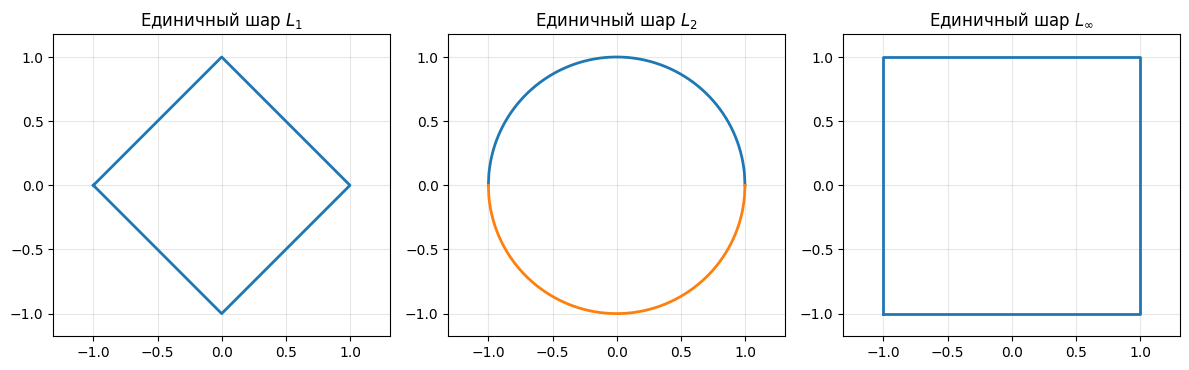

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1, 1, 500)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

# L1
axes[0].plot([-1, 0, 1, 0, -1], [0, 1, 0, -1, 0], linewidth=2)
axes[0].set_title("Единичный шар $L_1$")
axes[0].axis("equal")
axes[0].grid(True, alpha=0.3)

# L2
y = np.sqrt(1 - x**2)
axes[1].plot(x, y, linewidth=2)
axes[1].plot(x, -y, linewidth=2)
axes[1].set_title("Единичный шар $L_2$")
axes[1].axis("equal")
axes[1].grid(True, alpha=0.3)

# Linf
axes[2].plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], linewidth=2)
axes[2].set_title("Единичный шар $L_\infty$")
axes[2].axis("equal")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

На рисунке хорошо видно, что одна и та же фраза «все точки на расстоянии 1 от начала координат» зависит от того, **что именно считать расстоянием**.

Ниже показан ещё один полезный рисунок: один и тот же вектор на плоскости и три численных значения его норм.

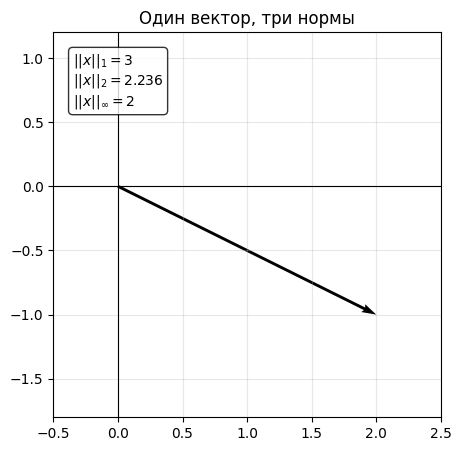

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

p = np.array([2, -1])

l1 = np.abs(p).sum()
l2 = np.sqrt((p**2).sum())
linf = np.max(np.abs(p))

plt.figure(figsize=(5, 5))
plt.quiver(0, 0, p[0], p[1], angles='xy', scale_units='xy', scale=1)
plt.xlim(-0.5, 2.5)
plt.ylim(-1.8, 1.2)
plt.grid(True, alpha=0.3)
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Один вектор, три нормы")
plt.text(0.05, 0.95,
         f"$||x||_1={l1}$\n$||x||_2={l2:.3f}$\n$||x||_\\infty={linf}$",
         transform=plt.gca().transAxes, va="top",
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
plt.show()

### Задание 1

Для вектора

$$
a=(2,-1,2)
$$

вычислите:

1. $\|a\|_1$;
2. $\|a\|_2$;
3. $\|a\|_\infty$.

После вычисления объясните, почему ответы различаются, хотя речь всё время идёт про один и тот же вектор.

<details>
<summary><b>Решение / комментарий преподавателю</b></summary>

Имеем:

$$
\|a\|_1=|2|+|-1|+|2|=5.
$$

$$
\|a\|_2=\sqrt{2^2+(-1)^2+2^2}=\sqrt{9}=3.
$$

$$
\|a\|_\infty=\max(2,1,2)=2.
$$

Важно проговорить, что разные нормы измеряют размер объекта по-разному:

- $L_1$ суммирует вклад всех координат;
- $L_2$ соответствует обычной геометрической длине;
- $L_\infty$ смотрит только на самый большой по модулю компонент.

</details>

# 3. Скалярное произведение

Для векторов одинаковой размерности

$$
a=(a_1,\dots,a_n), \qquad b=(b_1,\dots,b_n)
$$

скалярное произведение определяется как

$$
a\cdot b=\sum_{i=1}^n a_i b_i.
$$

Но у него есть и геометрический смысл:

$$
a\cdot b=\|a\|\|b\|\cos\alpha.
$$

Отсюда:

- если $a\cdot b>0$, угол острый;
- если $a\cdot b=0$, векторы перпендикулярны;
- если $a\cdot b<0$, угол тупой.

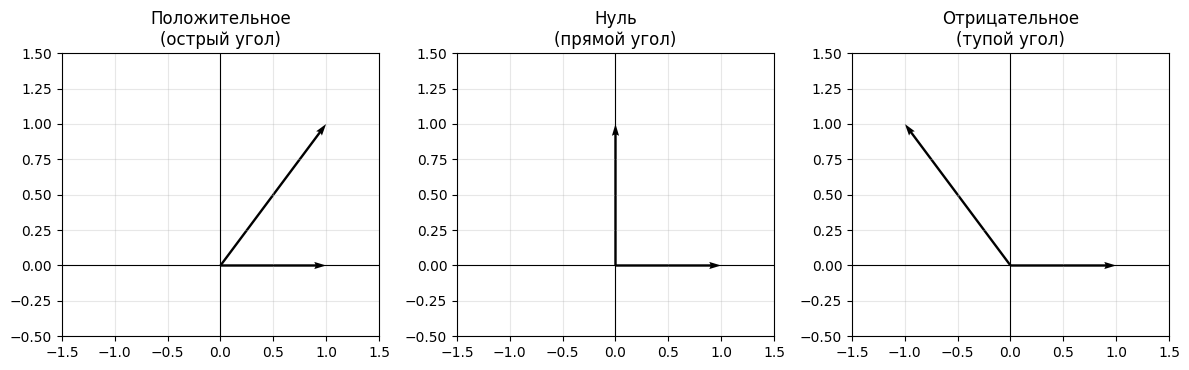

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

examples = [
    (np.array([1, 0]), np.array([1, 1]), "Положительное\n(острый угол)"),
    (np.array([1, 0]), np.array([0, 1]), "Нуль\n(прямой угол)"),
    (np.array([1, 0]), np.array([-1, 1]), "Отрицательное\n(тупой угол)")
]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

for ax, (u, v, title) in zip(axes, examples):
    ax.quiver(0, 0, u[0], u[1], angles="xy", scale_units="xy", scale=1)
    ax.quiver(0, 0, v[0], v[1], angles="xy", scale_units="xy", scale=1)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-0.5, 1.5)
    ax.grid(True, alpha=0.3)
    ax.set_title(title)

plt.tight_layout()
plt.show()

Ещё одна полезная интерпретация: скалярное произведение связано с **проекцией** одного вектора на другой. Если один вектор сильно «смотрит» в ту же сторону, произведение велико и положительно. Если в противоположную — отрицательно. Если векторы взаимно перпендикулярны, проекция равна нулю.

### Задание 2

Для векторов

$$
a=(2,-1,2), \qquad b=(1,3,-1)
$$

найдите:

1. скалярное произведение $a\cdot b$;
2. по знаку результата определите характер угла между векторами.

<details>
<summary><b>Решение / комментарий преподавателю</b></summary>

Считаем:

$$
a\cdot b = 2\cdot1 + (-1)\cdot3 + 2\cdot(-1)=2-3-2=-3.
$$

Результат отрицательный, значит угол между векторами тупой.

При желании можно отдельно подчеркнуть: точное значение угла не требуется, но знак произведения уже даёт качественную геометрическую информацию.

</details>

# 4. Векторное произведение

Векторное произведение определено в $\mathbb{R}^3$.

Для

$$
u=(u_x,u_y,u_z), \qquad v=(v_x,v_y,v_z)
$$

имеем

$$
u\times v=
\begin{pmatrix}
u_yv_z-u_zv_y\\
u_zv_x-u_xv_z\\
u_xv_y-u_yv_x
\end{pmatrix}.
$$

Результат — **новый вектор**, который:

- перпендикулярен обоим исходным векторам;
- направлен по правилу правой руки;
- имеет длину, равную площади параллелограмма, натянутого на $u$ и $v$.

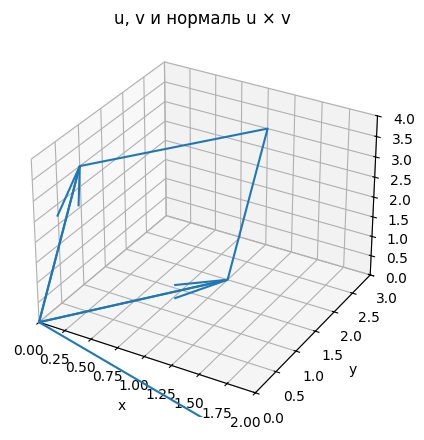

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

u = np.array([1, 2, 0])
v = np.array([0, 1, 3])
w = np.cross(u, v)

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection="3d")

ax.quiver(0, 0, 0, *u, length=1, normalize=False)
ax.quiver(0, 0, 0, *v, length=1, normalize=False)
ax.quiver(0, 0, 0, *w, length=1, normalize=False)

# параллелограмм
P = np.array([[0, 0, 0], u, u+v, v, [0, 0, 0]])
ax.plot(P[:, 0], P[:, 1], P[:, 2], linewidth=1.5)

ax.set_xlim(0, 2)
ax.set_ylim(0, 3)
ax.set_zlim(0, 4)
ax.set_title("u, v и нормаль u × v")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
plt.show()

На рисунке полезно проговорить сразу две вещи:

1. вектор $u\times v$ направлен **не в плоскости** исходных векторов, а **перпендикулярно ей**;
2. если поменять порядок местами, то

$$
v\times u = -(u\times v).
$$

То есть направление нормали меняется на противоположное.

### Задание 3

Для векторов

$$
u=(1,2,0), \qquad v=(0,1,3)
$$

найдите:

1. векторное произведение $u\times v$;
2. проверьте, что найденный вектор перпендикулярен и к $u$, и к $v$.

<details>
<summary><b>Решение / комментарий преподавателю</b></summary>

По формуле:

$$
u\times v=
\begin{pmatrix}
2\cdot3-0\cdot1\\
0\cdot0-1\cdot3\\
1\cdot1-2\cdot0
\end{pmatrix}
=
\begin{pmatrix}
6\\
-3\\
1
\end{pmatrix}.
$$

Проверка перпендикулярности:

$$
(6,-3,1)\cdot(1,2,0)=6-6+0=0,
$$

$$
(6,-3,1)\cdot(0,1,3)=0-3+3=0.
$$

Обе проверки дают ноль, значит вектор действительно перпендикулярен обоим исходным.

</details>

# 5. Дополнение: векторные поля, дивергенция и ротор

Этот блок не является центральным для реализации ЛР №3, но очень полезен для геометрической интуиции.

Рассмотрим плоское векторное поле

$$
F(x,y)=(F_1(x,y),F_2(x,y)).
$$

## Дивергенция

Показывает, есть ли в поле локальный **источник** или **сток**:

$$
\operatorname{div} F = \frac{\partial F_1}{\partial x} + \frac{\partial F_2}{\partial y}.
$$

## Ротор

В двумерном случае по сути отслеживает локальное **закручивание** поля:

$$
\operatorname{rot} F =
\frac{\partial F_2}{\partial x}-\frac{\partial F_1}{\partial y}.
$$

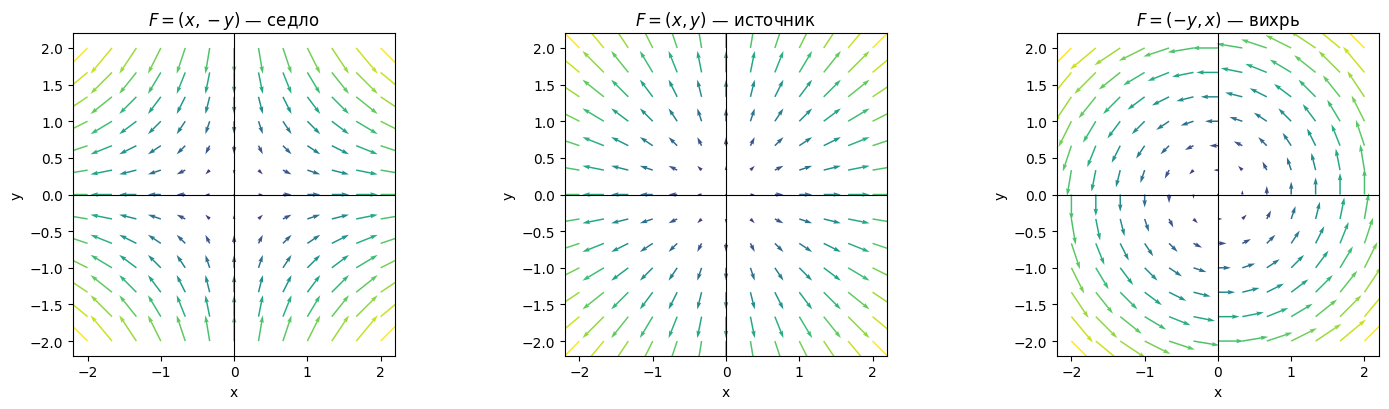

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-2, 2, 13)
y = np.linspace(-2, 2, 13)
X, Y = np.meshgrid(x, y)

fields = [
    (X, -Y, r"$F=(x,-y)$ — седло"),
    (X, Y,  r"$F=(x,y)$ — источник"),
    (-Y, X, r"$F=(-y,x)$ — вихрь")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for ax, (U, V, title) in zip(axes, fields):
    magnitude = np.sqrt(U**2 + V**2)
    ax.quiver(X, Y, U, V, magnitude, cmap="viridis", scale=25)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

Эти три картинки очень хорошо различаются по смыслу:

- **источник**: векторы расходятся от начала координат;
- **вихрь**: поле закручивается вокруг центра;
- **седло**: по одной оси поле «разбегается», а по другой «сбегается».

Именно такие визуальные образы помогают потом запомнить смысл дивергенции и ротора.

### Задание 4

Для трёх полей ниже определите тип поведения вблизи начала координат:

1. $F_1(x,y)=(x,y)$
2. $F_2(x,y)=(-y,x)$
3. $F_3(x,y)=(x,-y)$

Для каждого кратко скажите, что в нём преобладает: источник, вращение или седловая структура.

<details>
<summary><b>Решение / комментарий преподавателю</b></summary>

1. $F_1(x,y)=(x,y)$ — **источник**.  
   Векторы расходятся от начала координат. Здесь $\operatorname{div}F=2$, а ротор равен нулю.

2. $F_2(x,y)=(-y,x)$ — **вихрь**.  
   Поле закручивается вокруг начала координат. Здесь дивергенция равна нулю, а ротор ненулевой.

3. $F_3(x,y)=(x,-y)$ — **седло**.  
   По оси $x$ поле расходится, по оси $y$ — сходится.

Этот блок хорошо использовать как чисто геометрическое дополнение.

</details>

# 6. Матрица как линейное преобразование

Матрицу полезно воспринимать не только как таблицу чисел, но и как **оператор**, который преобразует векторы и фигуры.

Например, матрица может:

- растягивать;
- сжимать;
- отражать;
- сдвигать направления;
- менять ориентацию фигуры.

Если

$$
y=Ax,
$$

то вектор $x$ переходит в новый вектор $y$.

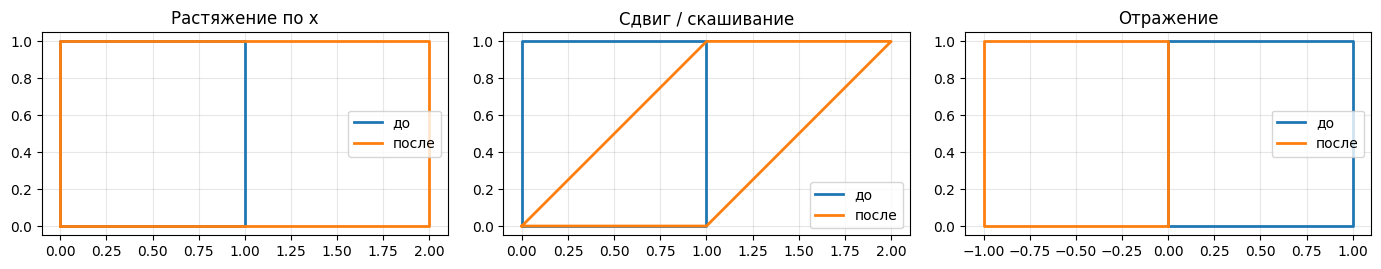

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

square = np.array([[0, 1, 1, 0, 0],
                   [0, 0, 1, 1, 0]])

transforms = [
    (np.array([[2, 0], [0, 1]]), "Растяжение по x"),
    (np.array([[1, 1], [0, 1]]), "Сдвиг / скашивание"),
    (np.array([[-1, 0], [0, 1]]), "Отражение")
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (M, title) in zip(axes, transforms):
    new = M @ square
    ax.plot(square[0], square[1], linewidth=2, label="до")
    ax.plot(new[0], new[1], linewidth=2, label="после")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

На этих рисунках особенно удобно обсуждать, что матрица действует **сразу на всю фигуру**, а не на одну точку.  
Это потом очень помогает понимать:

- определитель как изменение площади;
- обратную матрицу как «отмену» преобразования;
- композицию двух матриц как последовательность двух преобразований.

# 7. Умножение матриц

Если

$$
A \in \mathbb{R}^{m\times n}, \qquad B \in \mathbb{R}^{n\times k},
$$

то их произведение $C=AB$ имеет размер $m\times k$, а элементы вычисляются по формуле

$$
c_{ij}=\sum_{\ell=1}^{n} a_{i\ell}b_{\ell j}.
$$

Иными словами, каждый элемент $c_{ij}$ — это скалярное произведение:

- $i$-й строки матрицы $A$;
- $j$-го столбца матрицы $B$.

### Задание 5

Для матриц

$$
A=
\begin{pmatrix}
2 & 1\\
1 & 1
\end{pmatrix},
\qquad
B=
\begin{pmatrix}
1 & 2\\
0 & 1
\end{pmatrix}
$$

найдите произведение

$$
AB.
$$

<details>
<summary><b>Решение / комментарий преподавателю</b></summary>

Считаем построчно и по столбцам:

$$
AB=
\begin{pmatrix}
2\cdot1+1\cdot0 & 2\cdot2+1\cdot1\\
1\cdot1+1\cdot0 & 1\cdot2+1\cdot1
\end{pmatrix}
=
\begin{pmatrix}
2 & 5\\
1 & 3
\end{pmatrix}.
$$

Полезно отдельно проговорить, что порядок матриц важен: вообще говоря,

$$
AB \neq BA.
$$

</details>

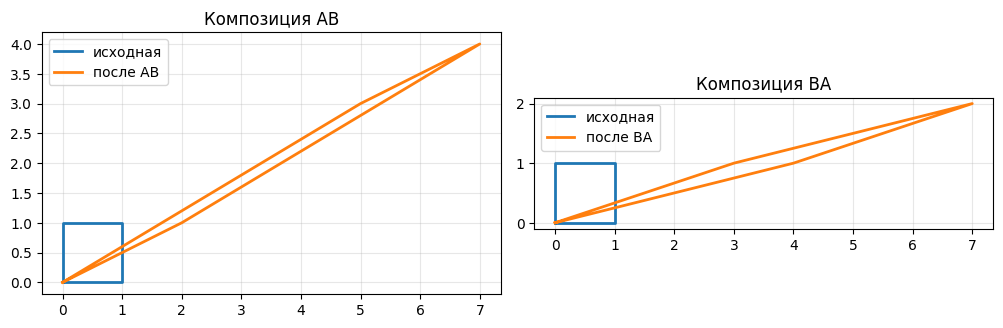

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[2, 1], [1, 1]])
B = np.array([[1, 2], [0, 1]])

square = np.array([[0, 1, 1, 0, 0],
                   [0, 0, 1, 1, 0]])

AB_shape = (A @ B) @ square
BA_shape = (B @ A) @ square

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(square[0], square[1], linewidth=2, label="исходная")
axes[0].plot(AB_shape[0], AB_shape[1], linewidth=2, label="после AB")
axes[0].set_aspect("equal")
axes[0].grid(True, alpha=0.3)
axes[0].set_title("Композиция AB")
axes[0].legend()

axes[1].plot(square[0], square[1], linewidth=2, label="исходная")
axes[1].plot(BA_shape[0], BA_shape[1], linewidth=2, label="после BA")
axes[1].set_aspect("equal")
axes[1].grid(True, alpha=0.3)
axes[1].set_title("Композиция BA")
axes[1].legend()

plt.tight_layout()
plt.show()

На этих двух рисунках видно, что сначала применить $B$, а потом $A$ — не то же самое, что сначала применить $A$, а потом $B$.

Это одна из ключевых причин, почему в коде нельзя бездумно переставлять матрицы местами.

# 8. Определитель

Для матрицы второго порядка

$$
A=
\begin{pmatrix}
a & b\\
c & d
\end{pmatrix}
$$

определитель равен

$$
\det A = ad-bc.
$$

Геометрический смысл:

- $|\det A|$ показывает, во сколько раз изменяется площадь;
- знак $\det A$ отражает изменение ориентации;
- если $\det A=0$, фигура «схлопывается», и матрица становится необратимой.

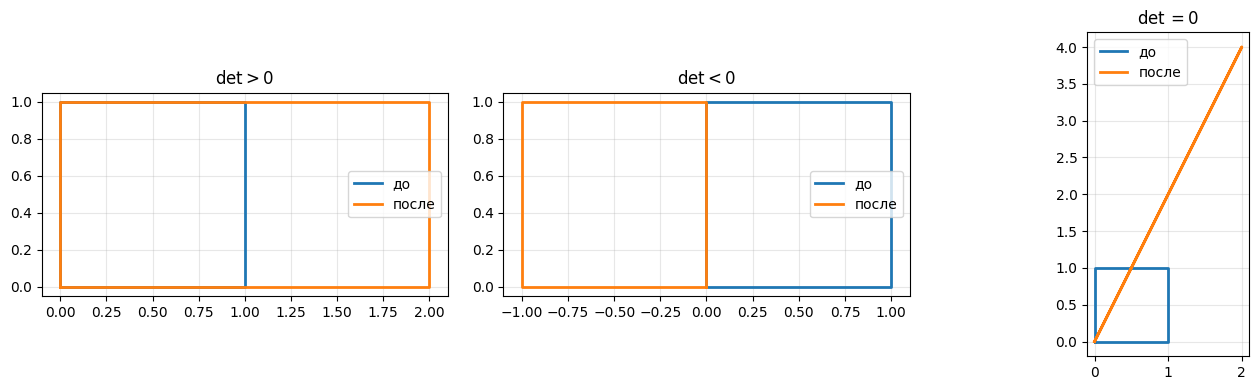

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

square = np.array([[0, 1, 1, 0, 0],
                   [0, 0, 1, 1, 0]])

examples = [
    (np.array([[2, 0], [0, 1]]), r"$\det>0$"),
    (np.array([[-1, 0], [0, 1]]), r"$\det<0$"),
    (np.array([[1, 1], [2, 2]]), r"$\det=0$")
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (M, title) in zip(axes, examples):
    new = M @ square
    ax.plot(square[0], square[1], linewidth=2, label="до")
    ax.plot(new[0], new[1], linewidth=2, label="после")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

### Задание 6

Для матрицы

$$
A=
\begin{pmatrix}
2 & 1\\
1 & 1
\end{pmatrix}
$$

найдите определитель и ответьте:

1. существует ли обратная матрица;
2. во сколько раз меняется площадь единичного квадрата.

<details>
<summary><b>Решение / комментарий преподавателю</b></summary>

Считаем:

$$
\det A = 2\cdot1 - 1\cdot1 = 1.
$$

Так как определитель не равен нулю, обратная матрица существует.

Модуль определителя равен $1$, значит площадь сохраняется.  
То есть единичный квадрат переходит в параллелограмм той же площади.

</details>

# 9. Обратная матрица

Если существует матрица $A^{-1}$ такая, что

$$
AA^{-1}=I,
$$

то она называется обратной к $A$.

Для матрицы второго порядка

$$
A=
\begin{pmatrix}
a & b\\
c & d
\end{pmatrix}
$$

имеем формулу

$$
A^{-1}=
\frac{1}{\det A}
\begin{pmatrix}
d & -b\\
-c & a
\end{pmatrix},
\qquad \det A\neq0.
$$

То есть обратная матрица существует только тогда, когда определитель не равен нулю.

### Задание 7

Найдите обратную матрицу к

$$
A=
\begin{pmatrix}
2 & 1\\
1 & 1
\end{pmatrix}
$$

и проверьте результат умножением.

<details>
<summary><b>Решение / комментарий преподавателю</b></summary>

Мы уже нашли:

$$
\det A=1.
$$

Следовательно,

$$
A^{-1}=
\begin{pmatrix}
1 & -1\\
-1 & 2
\end{pmatrix}.
$$

Проверка:

$$
A A^{-1}=
\begin{pmatrix}
2 & 1\\
1 & 1
\end{pmatrix}
\begin{pmatrix}
1 & -1\\
-1 & 2
\end{pmatrix}
=
\begin{pmatrix}
1 & 0\\
0 & 1
\end{pmatrix}.
$$

Значит обратная матрица найдена верно.

</details>

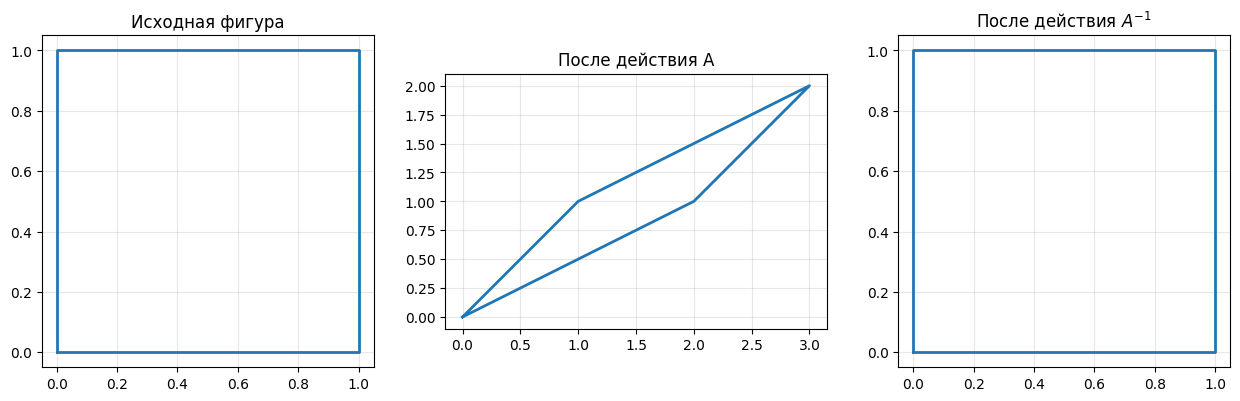

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[2, 1], [1, 1]])
A_inv = np.array([[1, -1], [-1, 2]])

square = np.array([[0, 1, 1, 0, 0],
                   [0, 0, 1, 1, 0]])

after_A = A @ square
back = A_inv @ after_A

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].plot(square[0], square[1], linewidth=2)
axes[0].set_title("Исходная фигура")
axes[0].set_aspect("equal")
axes[0].grid(True, alpha=0.3)

axes[1].plot(after_A[0], after_A[1], linewidth=2)
axes[1].set_title("После действия A")
axes[1].set_aspect("equal")
axes[1].grid(True, alpha=0.3)

axes[2].plot(back[0], back[1], linewidth=2)
axes[2].set_title("После действия $A^{-1}$")
axes[2].set_aspect("equal")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Последний рисунок особенно полезен для интуиции: матрица $A$ переводит фигуру в новое положение, а $A^{-1}$ возвращает её обратно.  
Это лучший наглядный способ объяснить смысл формулы

$$
AA^{-1}=I.
$$

# 10. Дополнительный блок: определитель 3×3 и идея метода Гаусса

В лабораторной работе достаточно использовать встроенные численные средства для проверки, но математически полезно помнить идею.

Если матрицу элементарными преобразованиями строк привести к верхнетреугольному виду, то её определитель равен произведению диагональных элементов с учётом:

- перестановка двух строк меняет знак определителя;
- умножение строки на число меняет определитель во столько же раз;
- прибавление к строке кратной другой строки определитель не меняет.

Это и есть связь с методом Гаусса.

### Задание 8

Найдите определитель матрицы

$$
M=
\begin{pmatrix}
2 & 1 & -1\\
1 & 3 & 2\\
1 & 0 & 1
\end{pmatrix}
$$

через приведение к верхнетреугольному виду.

<details>
<summary><b>Решение / комментарий преподавателю</b></summary>

Возьмём

$$
R_2 \leftarrow R_2-\frac12 R_1,\qquad
R_3 \leftarrow R_3-\frac12 R_1.
$$

Получаем

$$
\begin{pmatrix}
2 & 1 & -1\\
0 & \frac52 & \frac52\\
0 & -\frac12 & \frac32
\end{pmatrix}.
$$

Теперь устраним элемент под вторым ведущим:

$$
R_3 \leftarrow R_3+\frac15 R_2.
$$

Получаем верхнетреугольную матрицу

$$
\begin{pmatrix}
2 & 1 & -1\\
0 & \frac52 & \frac52\\
0 & 0 & 2
\end{pmatrix}.
$$

Мы использовали только прибавление кратных строк, поэтому определитель не изменился.

Тогда

$$
\det M = 2\cdot \frac52 \cdot 2 = 10.
$$

</details>

# 11. Что нужно уметь перед ЛР №3

К моменту выполнения лабораторной работы полезно уверенно понимать:

| Операция | Что означает результат | Как проверить |
|---|---|---|
| Норма вектора | длина / размер вектора | сравнить по формуле |
| Скалярное произведение | связь с углом | знак и ручной подсчёт |
| Векторное произведение | нормаль к плоскости | перпендикулярность через скалярное произведение |
| Умножение матриц | композиция преобразований | ручной расчёт нескольких элементов |
| Определитель | изменение площади / обратимость | знак, модуль, нулевое или ненулевое значение |
| Обратная матрица | обратное преобразование | проверка по $AA^{-1}=I$ |

Главный принцип тот же, что и в предыдущих семинарах:

сначала понять **математический смысл**, а потом уже переносить это в код.

# 12. Вопросы для обсуждения

1. Почему для одного и того же вектора нормы $L_1$, $L_2$ и $L_\infty$ различаются?
2. Что можно понять про угол между векторами по знаку скалярного произведения?
3. Почему результат векторного произведения — именно вектор, а не число?
4. Что показывает модуль векторного произведения?
5. Почему порядок умножения матриц важен?
6. Что геометрически означает определитель?
7. Почему при $\det A=0$ обратная матрица не существует?
8. Чем полезна интерпретация матрицы как преобразования фигуры?
9. Чем источник отличается от вихря с точки зрения картинок поля?
10. Почему при перестановке строк в методе Гаусса меняется знак определителя?